In [6]:
# Cell 1: Imports and Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import pyedflib
import os
import random
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler

np.random.seed(1)
random.seed(1)

data_dir = '../data/'

print("✓ Imports loaded")

✓ Imports loaded


In [7]:
# Cell 2: Parse all patient summary files

def parse_summary_file(patient_id):
    summary_path = os.path.join(data_dir, patient_id, f'{patient_id}-summary.txt')
    if not os.path.exists(summary_path):
        return []
    
    with open(summary_path, 'r') as f:
        content = f.read()
    
    seizures = []
    current_file = None
    lines = content.split('\n')
    i = 0
    while i < len(lines):
        line = lines[i].strip()
        if 'File Name:' in line:
            current_file = line.split('File Name:')[-1].strip()
        if current_file and ('Seizure' in line) and ('Start Time' in line):
            try:
                start_part = line.split('Start Time:')[-1].strip()
                start = int(''.join(filter(str.isdigit, start_part.split('seconds')[0])))
                for j in range(i+1, min(i+5, len(lines))):
                    next_line = lines[j].strip()
                    if 'End Time' in next_line:
                        end_part = next_line.split('End Time:')[-1].strip()
                        end = int(''.join(filter(str.isdigit, end_part.split('seconds')[0])))
                        seizures.append({
                            'file':    current_file,
                            'start':   start,
                            'end':     end,
                            'patient': patient_id
                        })
                        break
            except:
                pass
        i += 1
    return seizures

patient_ids = [f'chb{str(i).zfill(2)}' for i in range(1, 25) if i != 21]

all_patients_seizures = {}
for patient_id in patient_ids:
    seizures = parse_summary_file(patient_id)
    if len(seizures) > 0:
        all_patients_seizures[patient_id] = seizures

print(f"✓ {len(all_patients_seizures)} patients parsed")
print(f"✓ {sum(len(v) for v in all_patients_seizures.values())} total seizures")

✓ 23 patients parsed
✓ 194 total seizures


In [8]:
# Cell 3: Feature extraction functions — 69 features (3 features × 23 channels)

sfreq = 256

standard_channels = [
    'FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1',
    'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1',
    'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2',
    'FP2-F8', 'F8-T8', 'T8-P8', 'P8-O2',
    'FZ-CZ',  'CZ-PZ', 'P7-T7', 'T7-FT9',
    'FT9-FT10', 'FT10-T8', 'T8-P8'
]

def get_patient_channels(patient_id):
    summary_path = os.path.join(data_dir, patient_id, f'{patient_id}-summary.txt')
    valid_channels = []
    found_channels = False
    with open(summary_path, 'r', errors='ignore') as f:
        lines = f.readlines()
    for line in lines:
        line = line.strip()
        if 'Channels in EDF' in line:
            found_channels = True
            continue
        if found_channels and line.startswith('File Name:'):
            break
        if found_channels and line.startswith('Channel ') and ':' in line:
            parts = line.split(':')
            if len(parts) >= 2:
                try:
                    ch_name = parts[1].strip()
                    ch_idx = int(parts[0].replace('Channel', '').strip()) - 1
                    if ch_name != '-' and ch_name != '':
                        valid_channels.append((ch_idx, ch_name))
                except ValueError:
                    continue
    return valid_channels

def extract_eeg_from_file(patient_id, filename, channel_idx):
    filepath = os.path.join(data_dir, patient_id, filename)
    f = pyedflib.EdfReader(filepath)
    if channel_idx >= f.signals_in_file:
        f.close()
        return None
    sig = f.readSignal(channel_idx)
    f.close()
    return sig

def calculate_entropy(seg):
    hist, _ = np.histogram(seg, bins=50)
    hist = hist / np.sum(hist)
    hist = hist[hist > 0]
    return -np.sum(hist * np.log2(hist))

def calculate_line_length(seg):
    return np.sum(np.abs(np.diff(seg)))

def calculate_high_freq_power(seg, sfreq=256):
    nperseg = min(1024, len(seg))
    f, pxx = signal.welch(seg, sfreq, nperseg=nperseg)
    return np.sum(pxx[f >= 20])


def extract_features_from_window(eeg_channels, channel_info, start_sec, end_sec, sfreq):
    channel_lookup = {}
    for i, (ch_idx, ch_name) in enumerate(channel_info):
        if i < len(eeg_channels) and eeg_channels[i] is not None:
            channel_lookup[ch_name] = eeg_channels[i]
    
    start_idx = int(start_sec * sfreq)
    end_idx   = int(end_sec   * sfreq)
    
    # extract segments for all channels
    segments = {}
    for ch_name in standard_channels:
        if ch_name in channel_lookup:
            seg = channel_lookup[ch_name][start_idx:end_idx]
            segments[ch_name] = seg if len(seg) > 0 else None
        else:
            segments[ch_name] = None
    
    feature_vector = []
    feature_names  = []
    
    # per-channel features (3 × 23 = 69)
    for ch_name in standard_channels:
        seg = segments[ch_name]
        if seg is not None:
            feature_vector.extend([
                calculate_entropy(seg),
                calculate_line_length(seg),
                calculate_high_freq_power(seg, sfreq),
            ])
        else:
            feature_vector.extend([0, 0, 0])
        feature_names.extend([
            f'{ch_name}_entropy',
            f'{ch_name}_line_length',
            f'{ch_name}_hf_power',
        ])
    
    # mean coherence between every channel pair (253 pairs)
    for i in range(len(standard_channels)):
        for j in range(i+1, len(standard_channels)):
            ch1, ch2 = standard_channels[i], standard_channels[j]
            seg1, seg2 = segments[ch1], segments[ch2]
            if seg1 is not None and seg2 is not None:
                nperseg = min(1024, len(seg1))
                f, coh = signal.coherence(seg1, seg2, fs=sfreq, nperseg=nperseg)
                coh_val = np.mean(coh)
            else:
                coh_val = 0
            feature_vector.append(coh_val)
            feature_names.append(f'coh_{ch1}_{ch2}')
    
    return np.array(feature_vector), feature_names

# verify
test_seg = np.random.randn(256 * 120)
test_channels = [(i, ch) for i, ch in enumerate(standard_channels)]
test_eeg = [test_seg] * 23
fv, fn = extract_features_from_window(test_eeg, test_channels, 0, 120, sfreq)
print(f"✓ Feature vector size: {len(fv)}")
print(f"  Per-channel: 3 × 23 = {3*23}")
print(f"  Coherence pairs: {23*22//2}")
print(f"  Total: {len(fv)}")

def get_previous_file(patient_id, current_file):
    patient_dir = os.path.join(data_dir, patient_id)
    all_files = sorted([f for f in os.listdir(patient_dir) if f.endswith('.edf')])
    if current_file not in all_files:
        return None
    idx = all_files.index(current_file)
    return all_files[idx-1] if idx > 0 else None

def load_stitched_preictal(patient_id, sz_file, sz_start, preictal_sec, sfreq, channel_info):
    need_from_prev = preictal_sec - sz_start
    eeg_channels = []
    for ch_idx, ch_name in channel_info:
        try:
            eeg_current = extract_eeg_from_file(patient_id, sz_file, ch_idx)
            if eeg_current is None:
                eeg_channels.append(None)
                continue
            eeg_current = eeg_current[:int(sz_start * sfreq)]
            if need_from_prev > 0:
                prev_file = get_previous_file(patient_id, sz_file)
                if prev_file:
                    eeg_prev = extract_eeg_from_file(patient_id, prev_file, ch_idx)
                    if eeg_prev is not None:
                        eeg_channels.append(np.concatenate([
                            eeg_prev[-int(need_from_prev*sfreq):],
                            eeg_current
                        ]))
                    else:
                        eeg_channels.append(eeg_current)
                else:
                    eeg_channels.append(eeg_current)
            else:
                eeg_channels.append(eeg_current)
        except:
            eeg_channels.append(None)
    
    if need_from_prev > 0:
        return eeg_channels, 0, preictal_sec
    else:
        return eeg_channels, sz_start - preictal_sec, sz_start

print("✓ All functions defined")
print(f"  Features per window: 3 × 23 = {3*23}")

✓ Feature vector size: 322
  Per-channel: 3 × 23 = 69
  Coherence pairs: 253
  Total: 322
✓ All functions defined
  Features per window: 3 × 23 = 69


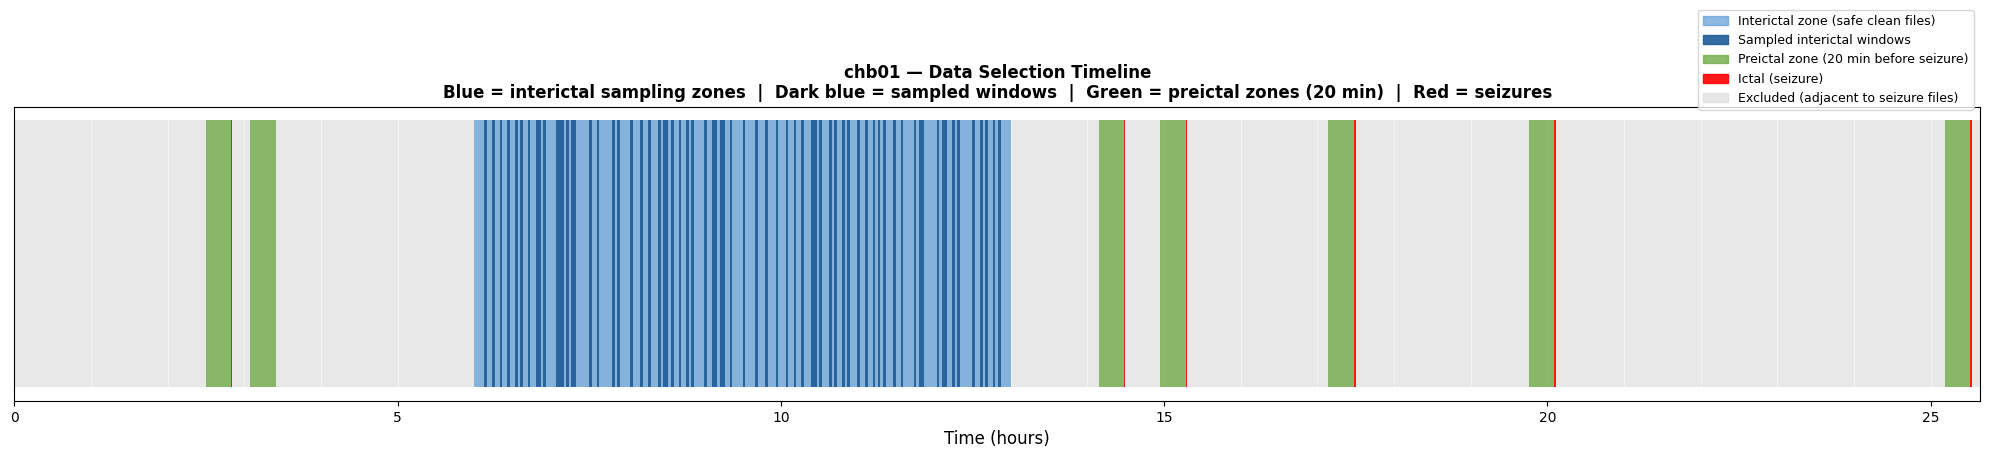

In [1]:
# Data Selection Figure — chb01 recording timeline
# Shows interictal sampling zones, preictal zones, and ictal events
# Similar to the train/test split figure from the prof

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# chb01 file information
# each file is 3600s (1 hour) except chb01_26 which is 2325s
file_durations = {
    'chb01_01': 3600, 'chb01_02': 3600, 'chb01_03': 3600,
    'chb01_04': 3600, 'chb01_05': 3600, 'chb01_06': 3600,
    'chb01_07': 3600, 'chb01_08': 3600, 'chb01_09': 3600,
    'chb01_10': 3600, 'chb01_11': 3600, 'chb01_12': 3600,
    'chb01_13': 3600, 'chb01_14': 3600, 'chb01_15': 3600,
    'chb01_16': 3600, 'chb01_17': 3600, 'chb01_18': 3600,
    'chb01_19': 3600, 'chb01_20': 3600, 'chb01_21': 3600,
    'chb01_22': 3600, 'chb01_23': 3600, 'chb01_24': 3600,
    'chb01_25': 3600, 'chb01_26': 2325,
}

# seizures
seizures_info = [
    {'file': 'chb01_03', 'start': 2996, 'end': 3036},
    {'file': 'chb01_04', 'start': 1467, 'end': 1494},
    {'file': 'chb01_15', 'start': 1732, 'end': 1772},
    {'file': 'chb01_16', 'start': 1015, 'end': 1066},
    {'file': 'chb01_18', 'start': 1720, 'end': 1810},
    {'file': 'chb01_21', 'start': 327,  'end': 420},
    {'file': 'chb01_26', 'start': 1862, 'end': 1963},
]

# clean baseline files used for interictal sampling
clean_files = ['chb01_07', 'chb01_08', 'chb01_09', 'chb01_10',
               'chb01_11', 'chb01_12', 'chb01_13']

# random interictal sample start times (from random.seed(1))
interictal_samples = {
    'chb01_07': [480, 2160, 2880, 3000, 3240,
                 840, 1200, 1560, 1920, 2520],
    'chb01_08': [240, 360, 960, 1800, 2880,
                 480, 720, 1080, 2160, 3120],
    'chb01_09': [1440, 1680, 1800, 2400, 3000,
                 120, 600, 960, 2040, 2760],
    'chb01_10': [0, 360, 720, 1800, 3360,
                 480, 840, 1200, 2400, 2880],
    'chb01_11': [1440, 1560, 2280, 2880, 3120,
                 240, 600, 960, 1800, 2520],
    'chb01_12': [0, 960, 1680, 2640, 2880,
                 360, 720, 1200, 2040, 3000],
    'chb01_13': [360, 840, 2160, 2760, 3000,
                 120, 480, 1080, 1800, 2400],
}

PREICTAL_SEC = 1200  # 20 minutes
WINDOW_SEC   = 120   # 2 minutes

# calculate cumulative start time for each file
file_list = sorted(file_durations.keys())
file_start_times = {}
cumulative = 0
for f in file_list:
    file_start_times[f] = cumulative
    cumulative += file_durations[f]

total_duration = cumulative

# convert to hours for x axis
def to_hours(seconds):
    return seconds / 3600

fig, ax = plt.subplots(figsize=(20, 5))

# draw full recording as grey background
ax.barh(0, to_hours(total_duration), left=0, height=0.4,
        color='lightgrey', alpha=0.5, zorder=1)

# draw each file boundary
for f in file_list:
    x = to_hours(file_start_times[f])
    ax.axvline(x, color='white', linewidth=0.5, zorder=2, alpha=0.7)

# draw interictal sampling zones (blue)
for cf in clean_files:
    x_start = to_hours(file_start_times[cf])
    x_end   = to_hours(file_start_times[cf] + file_durations[cf])
    ax.barh(0, x_end - x_start, left=x_start, height=0.4,
            color='#5B9BD5', alpha=0.7, zorder=3)
    
    # draw sampled windows as darker blue ticks
    if cf in interictal_samples:
        for s in interictal_samples[cf]:
            x_tick = to_hours(file_start_times[cf] + s)
            ax.barh(0, to_hours(WINDOW_SEC), left=x_tick, height=0.4,
                    color='#1F5C99', alpha=0.9, zorder=4)

# draw preictal zones (green) and seizures (red)
for sz in seizures_info:
    f = sz['file']
    if f not in file_start_times:
        continue
    
    file_abs_start = file_start_times[f]
    sz_abs_start   = file_abs_start + sz['start']
    sz_abs_end     = file_abs_start + sz['end']
    
    # preictal zone (20 min before seizure)
    preictal_abs_start = sz_abs_start - PREICTAL_SEC
    
    # check if need stitching from previous file
    if sz['start'] < PREICTAL_SEC:
        # preictal starts in previous file
        preictal_abs_start = sz_abs_start - PREICTAL_SEC
    
    ax.barh(0, to_hours(PREICTAL_SEC), 
            left=to_hours(preictal_abs_start), height=0.4,
            color='#70AD47', alpha=0.8, zorder=5)
    
    # ictal (seizure itself) — thin red bar
    ax.barh(0, to_hours(sz['end'] - sz['start']),
            left=to_hours(sz_abs_start), height=0.4,
            color='#FF0000', alpha=0.9, zorder=6)

# formatting
ax.set_xlabel('Time (hours)', fontsize=12)
ax.set_yticks([])
ax.set_xlim(0, to_hours(total_duration))
ax.set_title('chb01 — Data Selection Timeline\n'
             'Blue = interictal sampling zones  |  '
             'Dark blue = sampled windows  |  '
             'Green = preictal zones (20 min)  |  '
             'Red = seizures',
             fontsize=12, fontweight='bold')

# legend
legend_elements = [
    mpatches.Patch(color='#5B9BD5', alpha=0.7, label='Interictal zone (safe clean files)'),
    mpatches.Patch(color='#1F5C99', alpha=0.9, label='Sampled interictal windows'),
    mpatches.Patch(color='#70AD47', alpha=0.8, label='Preictal zone (20 min before seizure)'),
    mpatches.Patch(color='#FF0000', alpha=0.9, label='Ictal (seizure)'),
    mpatches.Patch(color='lightgrey', alpha=0.5, label='Excluded (adjacent to seizure files)'),
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=9,
          bbox_to_anchor=(1, 1.35))

plt.tight_layout()
plt.savefig('data_selection_timeline.png', dpi=300, bbox_inches='tight')
plt.show()